In [2]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,id,type
0,train_images/f0935e4c.png,0
1,train_images/45c48cce.png,1
2,train_images/7f39f831.png,1
3,train_images/13fe9d84.png,0
4,train_images/a5bfc9e0.png,1


(256, 256)


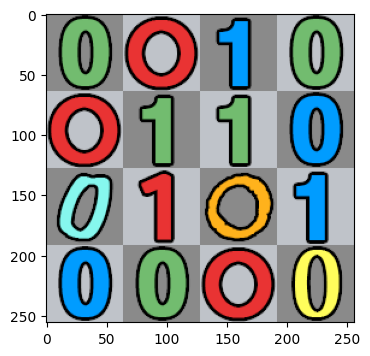

In [3]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("train_images/13fe9d84.png")

print(img.size)
plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.show()

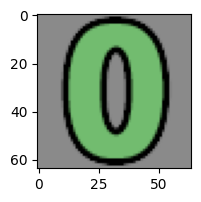

In [4]:
import numpy as np

img = np.array(Image.open("train_images/13fe9d84.png"))[:64, :64]

plt.figure(figsize=(2, 2))
plt.imshow(img)
plt.show()

In [10]:
import torch

num_epochs = 20
batch_size = 32
learning_rate = 0.0003

num_epochs

20

In [11]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

train_transforms = T.Compose([
    T.Resize((64, 64)),
    T.ToTensor()
])

test_transforms = T.Compose([
    T.Resize((64, 64)),
    T.ToTensor()
])

class MyDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.id.iloc[idx]
        img = Image.fromarray(np.array(Image.open(path))[:64, :64]).convert("RGB")
        img = self.transform(img)
        label = self.df.type.iloc[idx]
        label = torch.tensor(label, dtype=torch.float).view(1)
        return img, label

from sklearn.model_selection import train_test_split
df_1, df_2 = train_test_split(df_train, test_size=0.2, random_state=42)

train_dataset = MyDataset(df_1, train_transforms)
train_loader = DataLoader(train_dataset, batch_size=batch_size)

test_dataset = MyDataset(df_2, test_transforms)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

train_dataset[0][0][0][0][0]

tensor(0.5412)

In [12]:
import torch.nn as nn
import torchvision.models as models

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Flatten(),
            nn.LazyLinear(32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        x = self.net(x)
        return x

model = CNN().to("cuda")
criterion = nn.BCEWithLogitsLoss()
optim = torch.optim.AdamW(model.parameters(), lr=learning_rate)

model

CNN(
  (net): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): LazyLinear(in_features=0, out_features=32, bias=True)
    (8): ReLU()
    (9): Linear(in_features=32, out_features=16, bias=True)
    (10): ReLU()
    (11): Linear(in_features=16, out_features=1, bias=True)
  )
)

In [13]:
def train(epoch):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to("cuda"), labels.to("cuda")
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        optim.zero_grad()
        loss.backward()
        optim.step()
        total_loss += loss.item()
    print("Epoch ", epoch)
    print("Training loss ", total_loss/len(train_loader))

def test(epoch):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to("cuda"), labels.to("cuda")
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
    print("Validation loss ", total_loss/len(test_loader))

In [14]:
for epoch in range(1, num_epochs+1):
    train(epoch)
    test(epoch)

Epoch  1
Training loss  0.6797768890857696
Validation loss  0.6446927587191263
Epoch  2
Training loss  0.6189915120601654
Validation loss  0.5626587669054667
Epoch  3
Training loss  0.5089952319860458
Validation loss  0.4220489760239919
Epoch  4
Training loss  0.34443407952785493
Validation loss  0.24811195333798727
Epoch  5
Training loss  0.17909788712859154
Validation loss  0.10951578120390575
Epoch  6
Training loss  0.0716012854129076
Validation loss  0.04016894226272901
Epoch  7
Training loss  0.026607204973697663
Validation loss  0.016431625622014206
Epoch  8
Training loss  0.01159362429752946
Validation loss  0.008343476491669813
Epoch  9
Training loss  0.006311265472322703
Validation loss  0.005066948477178812
Epoch  10
Training loss  0.004131804872304201
Validation loss  0.003642105342199405
Epoch  11
Training loss  0.0030290910974144934
Validation loss  0.0027883488995333514
Epoch  12
Training loss  0.002372509345877916
Validation loss  0.002246572713678082
Epoch  13
Training 

In [15]:
class FinalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.df.id.iloc[idx]
        img = Image.fromarray(np.array(Image.open(path))[:64, :64]).convert("RGB")
        img = self.transform(img)
        return img

final_dataset = FinalDataset(df_test, test_transforms)
final_loader = DataLoader(final_dataset, batch_size=batch_size)

final_dataset[0][0][0][0]

tensor(0.7490)

In [16]:
model.eval()
preds = []

with torch.no_grad():
    for inputs in final_loader:
        inputs = inputs.to("cuda")
        outputs = torch.sigmoid(model(inputs)).cpu().numpy().flatten()
        preds.extend(outputs)

preds = np.array(preds)
preds = (preds > 0.5).astype("int")
preds[:5]

array([0, 1, 0, 0, 1])

In [17]:
df_1 = pd.DataFrame({
    "subtaskID": 1,
    "ID": df_test.id,
    "answer": preds
})

df_1.head()

,subtaskID,ID,answer
0,1,test_images/cfcd2084.png,0
1,1,test_images/c4ca4238.png,1
2,1,test_images/c81e728d.png,0
3,1,test_images/eccbc87e.png,0
4,1,test_images/a87ff679.png,1


In [18]:
def pred_cell(img):
    img = torch.tensor(img, dtype=torch.float).permute(2, 0, 1).unsqueeze(0)
    img = img.to("cuda")
    output = torch.sigmoid(model(img))
    return int(output.item() > 0.5)

img = np.array(Image.open("train_images/13fe9d84.png").convert("RGB"))[:64, :64]
pred_cell(img)

0

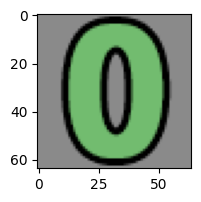

In [19]:
def get_patches(img):
    img = np.array(img)
    patches = []
    for i in range(0, 256, 64):
        for j in range(0, 256, 64):
            patch = img[i:i+64, j:j+64]
            patches.append(patch)
    return patches

img = Image.open("train_images/13fe9d84.png").convert("RGB")
plt.figure(figsize=(2, 2))
plt.imshow(get_patches(img)[0])
plt.show()

In [20]:
def binary_to_int(vals):
    ok = vals[0]
    vals = list(reversed(vals))
    suma = 0
    k = 1
    for val in vals:
        if val == 1:
            suma += k
        k *= 2
    if ok == 1:
        suma -= 2**16
    return suma

binary_to_int([0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0])

9808

In [21]:
def get_pred(img):
    patches = get_patches(img)
    preds = [pred_cell(patch) for patch in patches]
    val = binary_to_int(preds)
    return val

get_pred(Image.open("train_images/13fe9d84.png").convert("RGB"))

9808

In [22]:
preds = []

for path in df_test.id:
    img = Image.open(path).convert("RGB")
    preds.append(get_pred(img))

preds[:5]

[27608, -15237, 2146, 19936, -3361]

In [23]:
df_2 = pd.DataFrame({
    "subtaskID": 2,
    "ID": df_test.id,
    "answer": preds
})

df_2.head()

,subtaskID,ID,answer
0,2,test_images/cfcd2084.png,27608
1,2,test_images/c4ca4238.png,-15237
2,2,test_images/c81e728d.png,2146
3,2,test_images/eccbc87e.png,19936
4,2,test_images/a87ff679.png,-3361


In [24]:
submission = pd.concat([df_1, df_2])
submission

,subtaskID,ID,answer
0,1,test_images/cfcd2084.png,0
1,1,test_images/c4ca4238.png,1
2,1,test_images/c81e728d.png,0
3,1,test_images/eccbc87e.png,0
4,1,test_images/a87ff679.png,1
...,...,...,...
95,2,test_images/812b4ba2.png,-1372
96,2,test_images/26657d5f.png,515
97,2,test_images/e2ef524f.png,30631
98,2,test_images/ed3d2c21.png,15617


In [25]:
submission.to_csv("submission.csv", index=False)